# 变分积分器求解一维简谐振子

- [周详](xiangzhou@whu.edu.cn)
- 武汉大学
- 2026年9月28日

例 1 把变分积分器用在自由落体上：位置精确到机器精度——但那是**二次多项式解**的特权。本例换上力随状态变化的第一个系统：一维简谐振子。第二章例 4 已经用解析公式 $E_n = E_0(1+z^4/4)^n$ 判了 RK2 的"死刑"——能量每步膨胀、无界增长；欧拉法更差（$E_n = E_0(1+z^2)^n$）。变分积分器能活成什么样？

运动方程与拉格朗日量（$\omega_0 = \sqrt{k/m}$，$z = \omega_0 h$ 为无量纲步长）：

$$
m\ddot{x} = -kx, \qquad L(x, \dot x) = \tfrac{1}{2}m\dot x^2 - \tfrac{1}{2}kx^2
$$

沿用例 1 的**中点离散拉格朗日量**（区间平均速度 + 区间中点位置）：

$$
L_d(x_k, x_{k+1}) = \frac{m(x_{k+1}-x_k)^2}{2h} - \frac{h k}{8}(x_k + x_{k+1})^2
$$

代入离散变分原理，DEL 展开后（注意：右端不再是例 1 的常数 $gh^2$，**力进入了系数**）：

$$
2x_k - x_{k-1} - x_{k+1} = \frac{z^2}{4}\left(x_{k-1} + 2x_k + x_{k+1}\right)
\;\;\Longrightarrow\;\;
\boxed{\,x_{k+1} = 2c\,x_k - x_{k-1}, \quad c = \frac{1 - z^2/4}{1 + z^2/4}\,}
$$

启动步仍由离散 Legendre 变换 $p_0 = m v_0$ 反解，节点动量为

$$
\frac{p_k}{m} = \frac{x_{k+1}-x_k}{h} + \frac{\omega_0^2 h}{4}(x_k + x_{k+1}),
\qquad
x_1 = \frac{x_0(1 - z^2/4) + h v_0}{1 + z^2/4}
$$

$c$ 恰是某个角 $\theta$ 的余弦——递推是一个**旋转**。总机械能 $E = \tfrac{1}{2}mv^2 + \tfrac{1}{2}kx^2$，参数与第二章例 4 完全一致（$x_0 = 1,\ v_0 = 0,\ k = m = 1$，$E_0 = 0.5$ J）。

**运行之前，先把你的预测写下来**：

1. RK2 的每步能量比 $1 + z^4/4$ 恒大于 1——变分积分器的能量会怎么走？无界、有界振荡、还是……？
2. 解是 $\cos t$，不再是二次多项式——位置还会精确吗？误差会长成什么样？
3. 数值周期偏大还是偏小？把步长加到 $z = 2$（许多显式方法的"雷区"）会怎样？

带着预测运行下面的代码，逐条对照。

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 字体配置：按操作系统自动选择中文字体，
# 西文与数学公式用 Times New Roman 风格（STIX）
import platform
system = platform.system()
if system == 'Darwin':
    cn_font = 'Songti SC'
elif system == 'Windows':
    cn_font = 'SimSun'
else:  # Linux
    cn_font = 'Noto Serif CJK SC'

plt.rcParams['font.family'] = [cn_font, 'Times New Roman']
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['axes.unicode_minus'] = False

In [2]:
def variational_oscillator(x0, v0, k, m, h, n_steps):
    """变分积分器（中点 L_d）求解简谐振子
    DEL：x_{k+1} = 2c x_k - x_{k-1}，c = (1-z^2/4)/(1+z^2/4)
    启动步与节点动量均由离散 Legendre 变换给出"""
    om0 = np.sqrt(k / m)
    z = om0 * h
    c = (1 - z**2 / 4) / (1 + z**2 / 4)
    t = np.arange(n_steps + 1) * h
    x = np.empty(n_steps + 2)                # 多算一个节点，末动量才够用
    x[0] = x0
    x[1] = (x0 * (1 - z**2 / 4) + h * v0) / (1 + z**2 / 4)   # 由 p_0 = m v_0 反解
    for j in range(1, n_steps + 1):
        x[j + 1] = 2 * c * x[j] - x[j - 1]   # DEL 递推（纯旋转）
    v = (x[1:] - x[:-1]) / h + (om0**2 * h / 4) * (x[1:] + x[:-1])   # p_k / m
    return t, x[:-1].copy(), v


def rk2_midpoint_oscillator(x0, v0, k, m, h, n_steps):
    """RK2 中点法求解简谐振子（第二章例 4 原格式）"""
    t = np.arange(n_steps + 1) * h
    x = np.empty(n_steps + 1)
    v = np.empty(n_steps + 1)
    x[0], v[0] = x0, v0
    for n in range(n_steps):
        v_mid = v[n] - 0.5 * h * (k / m) * x[n]
        x_mid = x[n] + 0.5 * h * v[n]
        x[n + 1] = x[n] + h * v_mid
        v[n + 1] = v[n] - h * (k / m) * x_mid
    return t, x, v


def forward_euler_oscillator(x0, v0, k, m, h, n_steps):
    """前向欧拉法求解简谐振子（第二章例 4 原格式）"""
    t = np.arange(n_steps + 1) * h
    x = np.empty(n_steps + 1)
    v = np.empty(n_steps + 1)
    x[0], v[0] = x0, v0
    for n in range(n_steps):
        v[n + 1] = v[n] - h * (k / m) * x[n]
        x[n + 1] = x[n] + h * v[n]
    return t, x, v


def measure_period(t, x):
    """过零点法测周期：上升过零点（线性插值）的平均间距"""
    s = np.where(np.diff(np.signbit(x)) & (x[1:] > 0))[0]
    tc = t[s] - x[s] * (t[s + 1] - t[s]) / (x[s + 1] - x[s])
    return np.mean(np.diff(tc))


# 参数（与第二章例 4 完全一致）
x0, v0 = 1.0, 0.0
k, m = 1.0, 1.0
om0 = np.sqrt(k / m)
T0 = 2 * np.pi / om0
h = 0.1
t_end = 30.0
z = om0 * h
n_steps = int(t_end / h)

t, x_vi, v_vi = variational_oscillator(x0, v0, k, m, h, n_steps)
t, x_rk, v_rk = rk2_midpoint_oscillator(x0, v0, k, m, h, n_steps)
t, x_eu, v_eu = forward_euler_oscillator(x0, v0, k, m, h, n_steps)

x_exact = x0 * np.cos(om0 * t) + v0 / om0 * np.sin(om0 * t)
E0 = 0.5 * m * v0**2 + 0.5 * k * x0**2
E_vi = 0.5 * m * v_vi**2 + 0.5 * k * x_vi**2
E_rk = 0.5 * m * v_rk**2 + 0.5 * k * x_rk**2
E_eu = 0.5 * m * v_eu**2 + 0.5 * k * x_eu**2

theta = 2 * np.arctan(z / 2)
print(f'z = {z:.2f}：c = cos θ = {(1 - z**2 / 4) / (1 + z**2 / 4):.10f}，θ = 2 arctan(z/2) = {theta:.10f} rad')
print(f'数值周期理论值 T = 2πh/θ = {2 * np.pi * h / theta:.6f} s（真实 T0 = {T0:.6f} s，偏慢 {100 * (2 * np.pi * h / theta / T0 - 1):.4f}%）\n')

print(f'{"":18}{"变分积分器":>16}{"RK2":>14}{"前向欧拉":>14}')
print(f'{"位置最大误差":16}{np.abs(x_vi - x_exact).max():>16.4f}{np.abs(x_rk - x_exact).max():>14.4f}{np.abs(x_eu - x_exact).max():>14.4f}')
print(f'{"末能量 E/E0":17}{E_vi[-1] / E0:>16.8f}{E_rk[-1] / E0:>14.6f}{E_eu[-1] / E0:>14.4f}')
print(f'{"理论 E/E0":18}{"（严格 = 1）":>16}{(1 + z**4 / 4)**n_steps:>14.6f}{(1 + z**2)**n_steps:>14.4f}')
print(f'{"|E/E0 - 1| 最大":16}{np.abs(E_vi / E0 - 1).max():>16.2e}{np.abs(E_rk / E0 - 1).max():>14.2e}{np.abs(E_eu / E0 - 1).max():>14.2e}')

print(f'\n周期实测：变分积分器 {measure_period(t, x_vi):.4f} s，RK2 {measure_period(t, x_rk):.4f} s，真实 {T0:.4f} s')
print(f'相位误差（t = 30 s）：变分积分器慢 {-z**2 / 12 * om0 * t_end:+.4f} rad，RK2 快 {+z**2 / 6 * om0 * t_end:+.4f} rad——恰好两倍、反号')

z = 0.10：c = cos θ = 0.9950124688，θ = 2 arctan(z/2) = 0.0999167914 rad
数值周期理论值 T = 2πh/θ = 6.288418 s（真实 T0 = 6.283185 s，偏慢 0.0833%）

                             变分积分器           RK2          前向欧拉
位置最大误差                    0.0249        0.0499        3.1184
末能量 E/E0               1.00000000      1.007528       19.7885
理论 E/E0                   （严格 = 1）      1.007528       19.7885
|E/E0 - 1| 最大           2.84e-14      7.53e-03      1.88e+01

周期实测：变分积分器 6.2884 s，RK2 6.2728 s，真实 6.2832 s
相位误差（t = 30 s）：变分积分器慢 -0.0250 rad，RK2 快 +0.0500 rad——恰好两倍、反号


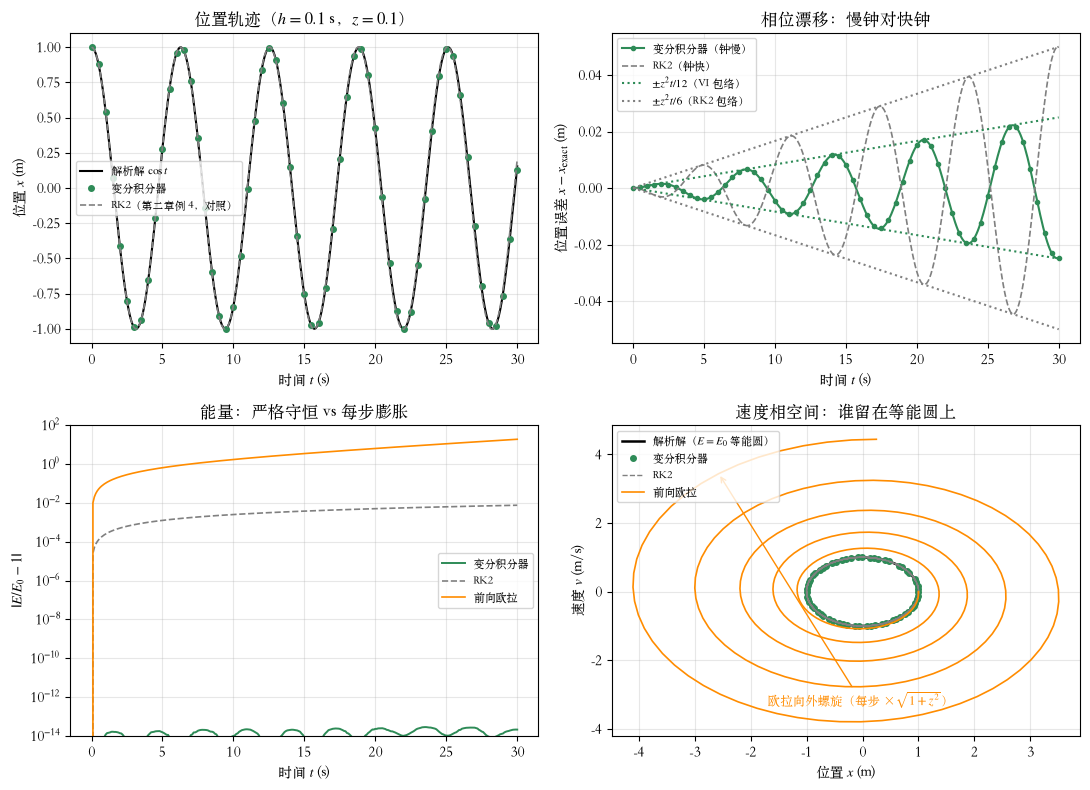

In [3]:
fig, axs = plt.subplots(2, 2, figsize=(11, 8))

# (a) 位置轨迹（欧拉 30 s 内已偏离太多，放到下图）
ax = axs[0, 0]
ax.plot(t, x_exact, '-', color='black', lw=1.5, label='解析解 $\\cos t$')
ax.plot(t, x_vi, 'o', color='seagreen', ms=4, markevery=5, label='变分积分器')
ax.plot(t, x_rk, '--', color='gray', lw=1.2, label='RK2（第二章例 4，对照）')
ax.set_xlabel('时间 $t$ (s)')
ax.set_ylabel('位置 $x$ (m)')
ax.set_title('位置轨迹（$h = 0.1$ s，$z = 0.1$）')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# (b) 位置误差：两个"钟"一快一慢，恰好两倍、反号
ax = axs[0, 1]
ax.plot(t, x_vi - x_exact, 'o-', color='seagreen', ms=3, markevery=5, label='变分积分器（钟慢）')
ax.plot(t, x_rk - x_exact, '--', color='gray', lw=1.2, label='RK2（钟快）')
tt = np.linspace(0, t_end, 10)
ax.plot(tt, -z**2 / 12 * om0 * tt, ':', color='seagreen', lw=1.5, label='$\\pm z^2 t/12$（VI 包络）')
ax.plot(tt, z**2 / 12 * om0 * tt, ':', color='seagreen', lw=1.5)
ax.plot(tt, z**2 / 6 * om0 * tt, ':', color='gray', lw=1.5, label='$\\pm z^2 t/6$（RK2 包络）')
ax.plot(tt, -z**2 / 6 * om0 * tt, ':', color='gray', lw=1.5)
ax.set_xlabel('时间 $t$ (s)')
ax.set_ylabel('位置误差 $x - x_{\\rm exact}$ (m)')
ax.set_title('相位漂移：慢钟对快钟')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# (c) 能量（对数纵轴）
ax = axs[1, 0]
ax.semilogy(t, np.abs(E_vi / E0 - 1) + 1e-300, '-', color='seagreen', lw=1.4, label='变分积分器')
ax.semilogy(t, np.abs(E_rk / E0 - 1), '--', color='gray', lw=1.2, label='RK2')
ax.semilogy(t, np.abs(E_eu / E0 - 1), '-', color='darkorange', lw=1.2, label='前向欧拉')
ax.set_ylim(1e-14, 1e2)
ax.set_xlabel('时间 $t$ (s)')
ax.set_ylabel('$|E/E_0 - 1|$')
ax.set_title('能量：严格守恒 vs 每步膨胀')
ax.legend(fontsize=8)
ax.grid(alpha=0.3, which='both')

# (d) 速度相空间 (x, v)：等能线为半径 1 的圆
ax = axs[1, 1]
th_c = np.linspace(0, 2 * np.pi, 200)
ax.plot(np.cos(th_c), np.sin(th_c), '-', color='black', lw=1.8, label='解析解（$E = E_0$ 等能圆）')
ax.plot(x_vi, v_vi, 'o', color='seagreen', ms=4, markevery=5, label='变分积分器')
ax.plot(x_rk, v_rk, '--', color='gray', lw=1.0, label='RK2')
ax.plot(x_eu, v_eu, '-', color='darkorange', lw=1.2, label='前向欧拉')
ax.annotate('欧拉向外螺旋（每步 ×$\\sqrt{1+z^2}$）', xy=(x_eu[-8], v_eu[-8]),
            xytext=(-1.7, -3.3), fontsize=9, color='darkorange',
            arrowprops=dict(arrowstyle='->', color='darkorange'))
ax.set_xlabel('位置 $x$ (m)')
ax.set_ylabel('速度 $v$ (m/s)')
ax.set_title('速度相空间：谁留在等能圆上')
ax.legend(fontsize=8, loc='upper left')
ax.grid(alpha=0.3)

plt.tight_layout()
fig.savefig('outputs/2_simple_oscillator_variational.pdf', bbox_inches='tight')   # 矢量图导出
plt.show()

**对照预测 1–3**：

- **能量严格守恒——不是"有界振荡"，是恒等**：变分积分器的 $|E/E_0 - 1|$ 全程压在 $3\times 10^{-14}$（纯舍入）；RK2 末能量 $\times 1.007528$，与第二章例 4 的公式 $(1+z^4/4)^{300}$ **逐位一致**；欧拉 $\times 19.79 = (1.01)^{300}$ 也逐位一致。更妙的是：把 $z$ 加大到 $0.4$，变分积分器的能量偏差仍是 $10^{-15}$ 量级——**严格守恒不随步长变坏**。
- **位置不再精确——钟慢了**：误差线性增长到 $0.025$ m，包络 $\pm\frac{z^2}{12}\omega_0 t$；RK2 钟快，包络 $\pm\frac{z^2}{6}\omega_0 t$、误差 $0.050$ m——**两倍大小、恰好反号**。周期实测：变分积分器 $6.2884$ s（理论 $2\pi h/\theta$ 逐位符合），RK2 $6.2728$ s，真实 $6.2832$ s。
- **能量守恒 ≠ 轨迹精确**：变分积分器把能量守得死死的，相位却在慢慢落后——这是它与 RK2 交换的"错误类型"：RK2 振幅错（无界），变分积分器相位错（线性、且慢一半）。

## 为什么：旋转、恒等式与特权

- **DEL 是纯旋转**。递推 $x_{k+1} - 2c\,x_k + x_{k-1} = 0$ 的特征根是 $e^{\pm i\theta}$（$c = \cos\theta$），解为 $x_k = A\cos(k\theta + \varphi)$——**振幅 $A$ 严格不变**，对任何 $z$ 都成立（$c \in (-1, 1)$ 恒真，无条件稳定）。相比之下，RK2 的增长因子 $|1 + iz - z^2/2| = \sqrt{1 + z^4/4} > 1$ 对任何 $h$ 都大于 1——显式 RK 的特征根**永远**不在单位圆上。
- **能量为什么是恒等（两行代数）**。节点动量改写为 $\frac{p_k h}{m} = (1+\tfrac{z^2}{4})x_{k+1} - (1-\tfrac{z^2}{4})x_k$。记 $\alpha = 1+\tfrac{z^2}{4}$、$\beta = 1-\tfrac{z^2}{4}$，则 $\alpha\cos\theta = \beta$；对解 $x_j = A\cos(j\theta)$：
$$
\frac{p_k h}{m} = \alpha A\cos((k{+}1)\theta) - \beta A\cos k\theta = \cos k\theta\underbrace{(\alpha\cos\theta - \beta)}_{=\,0} - \alpha A\sin\theta\sin k\theta = -h\omega_0 A \sin k\theta
$$
（末步用了 $\alpha\sin\theta = z$，即 $\tan\frac{\theta}{2} = \frac{z}{2}$。）于是 $(x_k,\ p_k/m) = (A\cos k\theta,\ -\omega_0 A\sin k\theta)$ **精确落在真实等能椭圆上**：$E \equiv \frac{1}{2}kA^2$。第二章例 4 用解析律预言了 RK2 的无界指数增长；本例用代数恒等式证明了变分积分器的严格守恒——同一枚硬币的两面。
- **这是特权，常态是"有界振荡"**。严格恒等是**二次型能量**的特权（中点/Cayley 型离散精确保持二次不变量）。一般的系统——比如大振幅单摆——能量不是二次型，变分积分器只能保证能量在一个 $O(z^2)$ 的带内**永远振荡**、不系统性漂移。但那也已经完胜 RK2 的无界增长。
- **钟慢的根源**：$\theta = 2\arctan(z/2) = z - \tfrac{z^3}{12} + \cdots$，即 $\omega_{\rm num} = \omega_0(1 - \tfrac{z^2}{12} + \cdots)$——慢钟，相位误差 $-\tfrac{z^2}{12}\omega_0 t$ 线性累积。RK2 快钟 $+\tfrac{z^2}{6}$：恰好两倍、反号。每步只算**一次**右端（RK2 两次），二阶精度外加长期能量保证——性价比极高。

## 长时间模拟：恒等式能扛多久？

第二章例 4 的 RK2 到 $t = 10^4$ s 已膨胀 $\times 12.2$；例 1 的变分积分器在自由落体里被舍入的 $t^4$ 放大咬过一口。现在同样的考验：$t = 10^4$ s（$10^5$ 步），顺便把步长推到雷区 $z = 2$ 试一试。

**先预测，再运行**：

1. 变分积分器的能量带宽会随时间增长吗？会被舍入的累积放大（例 1 的 $t^4$ 教训）吗？
2. 欧拉法多久"出画"（超过 $10^3\,E_0$）？RK2 到 $10^4$ s 膨胀多少倍？
3. $z = 2$ 时：RK2 十步之后能量多大？变分积分器的轨迹长什么样、能量还守吗？

变分积分器（t = 1e4 s）：|E/E0 - 1| 最大 = 3.9e-13（30 s 时为 2.8e-14）
不变量 I = x_k^2 + x_{k+1}^2 - 2 c x_k x_{k+1}（c = cos θ）: 最大漂移 |I - I_0|/I_0 = 4.0e-13
RK2：E/E0 = 12.1821（理论 (1+z^4/4)^1e5 = 12.1821）
欧拉：E/E0 = 10^216（5000 s 处截断，再算会溢出）

===== 大步长雷区 z = 2（h = 2 s）=====
变分积分器节点序列：[ 1.  0. -1. -0.  1.  0. -1. -0.] → 周期恰为 4 步（8 s），能量偏差 0.0e+00
RK2 每步能量 ×5：10 步后 ×9.8e+06，20 步后 ×9.5e+13


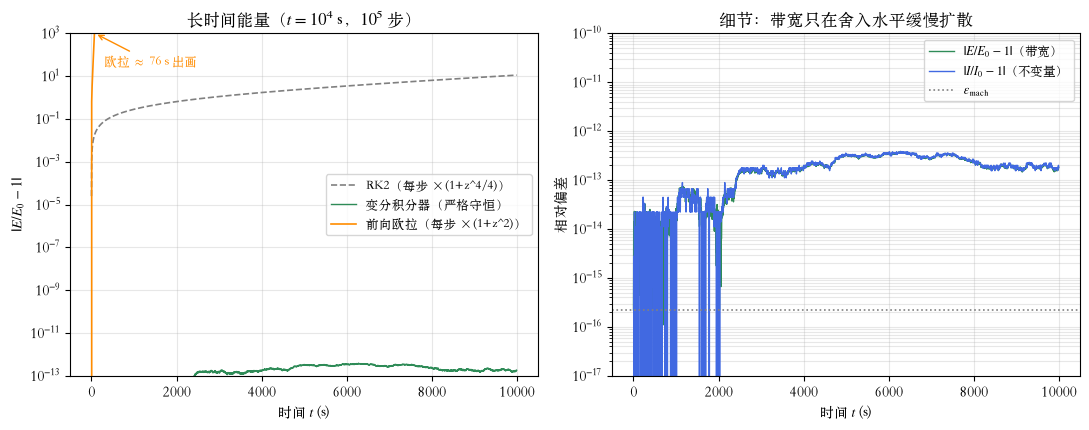

In [4]:
t_long = 1.0e4                      # 总时间 (s)
n_long = int(t_long / h)            # 1e5 步

tL, xL_vi, vL_vi = variational_oscillator(x0, v0, k, m, h, n_long)
_, xL_rk, vL_rk = rk2_midpoint_oscillator(x0, v0, k, m, h, n_long)
n_eu = int(5000.0 / h)             # 欧拉 5000 s 后能量溢出，只算到这里
_, xL_eu, vL_eu = forward_euler_oscillator(x0, v0, k, m, h, n_eu)

EL_vi = 0.5 * m * vL_vi**2 + 0.5 * k * xL_vi**2
EL_rk = 0.5 * m * vL_rk**2 + 0.5 * k * xL_rk**2
EL_eu = 0.5 * m * vL_eu**2 + 0.5 * k * xL_eu**2
c_long = (1 - z**2 / 4) / (1 + z**2 / 4)
I_long = xL_vi[:-1]**2 + xL_vi[1:]**2 - 2 * c_long * xL_vi[:-1] * xL_vi[1:]

print(f'变分积分器（t = 1e4 s）：|E/E0 - 1| 最大 = {np.abs(EL_vi / E0 - 1).max():.1e}（30 s 时为 {np.abs(E_vi / E0 - 1).max():.1e}）')
print('不变量 I = x_k^2 + x_{k+1}^2 - 2 c x_k x_{k+1}（c = cos θ）:'
      f' 最大漂移 |I - I_0|/I_0 = {np.abs(I_long - I_long[0]).max() / I_long[0]:.1e}')
print(f'RK2：E/E0 = {EL_rk[-1] / E0:.4f}（理论 (1+z^4/4)^1e5 = {(1 + z**4 / 4)**n_long:.4f}）')
print(f'欧拉：E/E0 = 10^{np.log10(EL_eu[-1] / E0):.0f}（5000 s 处截断，再算会溢出）')

print(f'\n===== 大步长雷区 z = 2（h = 2 s）=====')
h_b, n_b = 2.0, 20
tB, xB, vB = variational_oscillator(x0, v0, k, m, h_b, n_b)
_, xB_rk, vB_rk = rk2_midpoint_oscillator(x0, v0, k, m, h_b, n_b)
EB = 0.5 * m * vB**2 + 0.5 * k * xB**2
EB_rk = 0.5 * m * vB_rk**2 + 0.5 * k * xB_rk**2
print(f'变分积分器节点序列：{np.round(xB[:8], 6)} → 周期恰为 4 步（8 s），能量偏差 {np.abs(EB / E0 - 1).max():.1e}')
print(f'RK2 每步能量 ×5：10 步后 ×{EB_rk[10] / E0:.1e}，20 步后 ×{EB_rk[-1] / E0:.1e}')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4))
idx = slice(1, None, 50)           # 抽稀作图

# (a) 三方法长时间能量
ax1.semilogy(tL[idx], np.abs(EL_rk[idx] / E0 - 1), '--', color='gray', lw=1.2,
             label='RK2（每步 ×(1+z^4/4)）')
ax1.semilogy(tL[idx], np.abs(EL_vi[idx] / E0 - 1) + 1e-300, '-', color='seagreen', lw=1.0,
             label='变分积分器（严格守恒）')
ax1.semilogy(tL[:n_eu + 1:50], np.abs(EL_eu[::50] / E0 - 1), '-', color='darkorange', lw=1.2,
             label='前向欧拉（每步 ×(1+z^2)）')
ax1.set_ylim(1e-13, 1e3)
ax1.set_xlabel('时间 $t$ (s)')
ax1.set_ylabel('$|E/E_0 - 1|$')
ax1.set_title('长时间能量（$t = 10^4$ s，$10^5$ 步）')
ax1.annotate('欧拉 $\\approx$ 76 s 出画', xy=(80, 1e3), xytext=(300, 30), fontsize=9,
             color='darkorange', arrowprops=dict(arrowstyle='->', color='darkorange'))
ax1.legend(fontsize=9, loc='center right')
ax1.grid(alpha=0.3, which='both')

# (b) 变分积分器细节：能量带宽与不变量都在机器精度
ax2.semilogy(tL[idx], np.abs(EL_vi[idx] / E0 - 1) + 1e-300, '-', color='seagreen', lw=1.0,
             label='$|E/E_0 - 1|$（带宽）')
ax2.semilogy(tL[:-1:50], np.abs(I_long[::50] / I_long[0] - 1) + 1e-300, '-', color='royalblue', lw=1.0,
             label='$|I/I_0 - 1|$（不变量）')
ax2.axhline(2.2e-16, ls=':', color='gray', lw=1.2, label='$\\varepsilon_{\\rm mach}$')
ax2.set_ylim(1e-17, 1e-10)
ax2.set_xlabel('时间 $t$ (s)')
ax2.set_ylabel('相对偏差')
ax2.set_title('细节：带宽只在舍入水平缓慢扩散')
ax2.legend(fontsize=9, loc='upper right')
ax2.grid(alpha=0.3, which='both')

plt.tight_layout()
fig.savefig('outputs/2_simple_oscillator_variational_long.pdf', bbox_inches='tight')   # 矢量图导出
plt.show()

**读图**：

- **恒等式扛住了**：$10^5$ 步后变分积分器的能量带宽仍只有 $4\times 10^{-13}$（30 s 时 $3\times 10^{-14}$）——只是舍入的缓慢扩散，**没有任何系统性增长**。对照例 1 的教训：那里两步递推的舍入按 $t^4$ 放大，是因为位置 $x\sim t^2$ 越涨越大、大数相消越来越狠；这里轨道**有界**（$\max|x| = 1.000000$），舍入失去了放大的燃料。不变量 $I = x_k^2 + x_{k+1}^2 - 2c\,x_k x_{k+1}$ 的漂移也只有 $4\times 10^{-13}$。
- **对比仍在逐位兑现**：RK2 末能量 $\times 12.1821$，与 $(1+z^4/4)^{10^5}$ 逐位一致；欧拉约 76 s 就冲出画框（$\times 10^3$），5000 s 后能量大到溢出浮点数。
- **雷区 $z = 2$**：RK2 每步 $\times 5$，十步 $\times 10^7$；变分积分器的节点序列是 $1, 0, -1, 0, \cdots$——周期恰好 4 步、能量偏差为零，唯一的"错误"是钟慢了 27%（8 s 对 $2\pi$）。**任何步长都不爆炸，只是越走越慢**——这是变分格式的稳定本色。

## 结论与思考

**先对照引言的三个预测**（能量怎么走？位置还精确吗？周期偏哪边、大步长如何？），再记住几条：

- **变分积分器 = 旋转**：DEL 递推的特征根模长恒为 1，振幅严格不变；对二次型能量（振子）更是**能量恒等守恒**（Cayley/中点离散保二次不变量），任何步长都不失稳。
- **RK2 的宿命 vs 变分积分器的交换**：RK2 振幅错（每步 $\times(1+z^4/4)$，无界），变分积分器相位错（钟慢 $\frac{z^2}{12}$，线性累积、恰为 RK2 的一半且反号）。能量守恒与轨迹精确是两回事。
- **第二章例 4 ↔ 本例**：一边是解析预言的无界指数律，一边是解析证明的守恒恒等式——线性系统里，数值误差的命运可以**完全**算清楚。
- **有界轨道还救了舍入**：例 1 的 $t^4$ 舍入放大需要无界增长的位置当燃料；这里 $10^5$ 步后带宽仍在 $10^{-13}$。

**思考**：

1. **换一张 $L_d$**：改用端点形式 $L_d = \frac{m(x_{k+1}-x_k)^2}{2h} - \frac{h}{2}\left[V(x_k) + V(x_{k+1})\right]$ 重做推导——你会得到经典**蛙跳（Störmer–Verlet）**：$x_{k+1} = (2 - z^2)x_k - x_{k-1}$。求它的稳定区间与数值频率 $2\arcsin(z/2)$（钟快还是钟慢？）；它的能量还严格守恒吗，还是只剩 $O(z^2)$ 的有界振荡？（提示：把能量配在半节点上试试。）
2. 用不变量 $I = x_k^2 + x_{k+1}^2 - 2c\,x_k x_{k+1} = \text{const}$ 直接证明振幅守恒，并把 $I$ 翻译成 $(x, p)$ 平面上的"修正能量" $\tilde E = E + O(z^2)$ 的显式形式——它与真实椭圆差多少？
3. **非线性是下一站**：大振幅单摆的能量不是二次型，"恒等守恒"的特权没了。变分积分器还剩下什么承诺？后向误差分析说的"修正哈密顿量"能守多久？（这正是本章的主线。）
4. **等成本对比**：变分积分器每步 1 次右端、RK2 每步 2 次。用 RK2 取 $h/2$ 重跑本例：同成本下相位误差谁小？能量行为差在哪？